<a href="https://colab.research.google.com/github/nnannatu/Machine_Learning/blob/main/Lab_03.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
!pip install ucimlrepo
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo, list_available_datasets

sns.set(style="whitegrid")

In [4]:
# Fetch dataset (ID: 519)
heart_failure_clinical_records = fetch_ucirepo(id=519)

X = heart_failure_clinical_records.data.features
y = heart_failure_clinical_records.data.targets

print("X shape:", X.shape)   # (299, 12)
print("y shape:", y.shape)   # (299, 1)
print("\nTarget distribution:")
print(y['death_event'].value_counts())
print(f"Death rate: {y['death_event'].mean():.2%}")

X shape: (299, 12)
y shape: (299, 1)

Target distribution:
death_event
0    203
1     96
Name: count, dtype: int64
Death rate: 32.11%


In [5]:
df = pd.concat([X, y], axis=1)

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum().sum())   # 0 — no missing values

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
print(df.describe().T)

Shape: (299, 13)

Missing values:
0

Data types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
death_event                   int64
dtype: object

Descriptive statistics:
                          count           mean           std      min  \
age                       299.0      60.833893     11.894809     40.0   
anaemia                   299.0       0.431438      0.496107      0.0   
creatinine_phosphokinase  299.0     581.839465    970.287881     23.0   
diabetes                  299.0       0.418060      0.494067      0.0   
ejection_fraction         299.0      38.083612     11.834841     14.0   
high_b

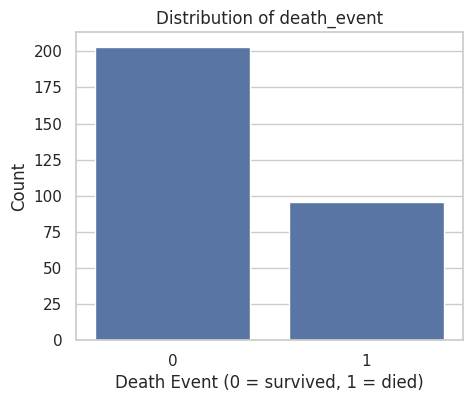

In [6]:
plt.figure(figsize=(5, 4))
sns.countplot(x='death_event', data=df)
plt.title('Distribution of death_event')
plt.xlabel('Death Event (0 = survived, 1 = died)')
plt.ylabel('Count')
plt.show()

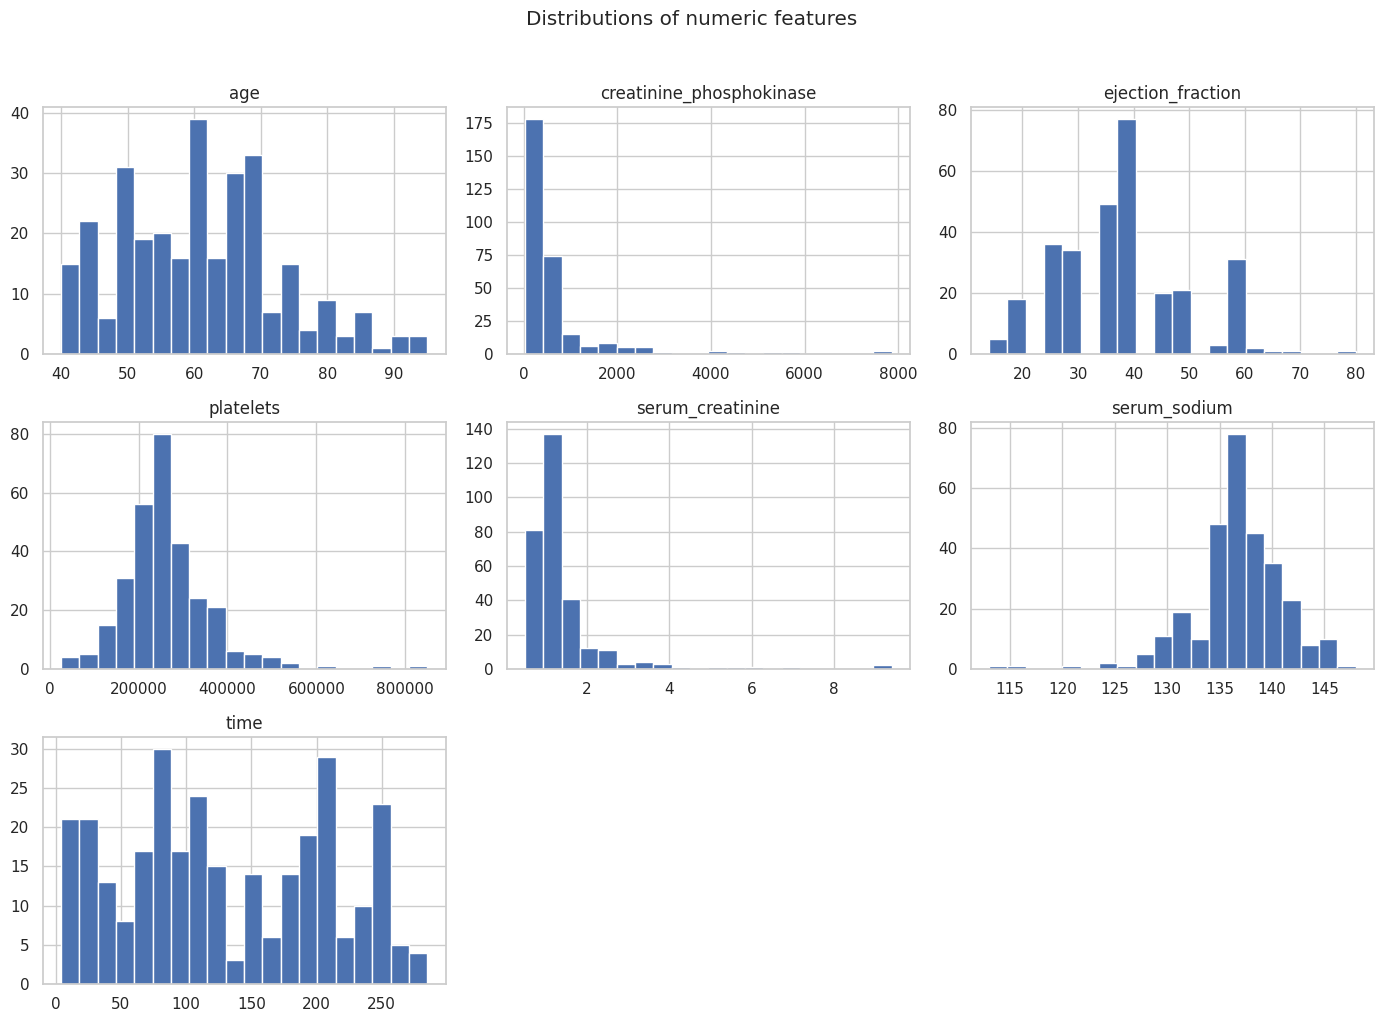

In [7]:
# Numeric continuous columns
num_cols = ['age', 'creatinine_phosphokinase', 'ejection_fraction',
            'platelets', 'serum_creatinine', 'serum_sodium', 'time']

# Boolean / binary columns
bool_cols = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']

# Histograms for numeric
df[num_cols].hist(bins=20, figsize=(14, 10))
plt.suptitle('Distributions of numeric features', y=1.02)
plt.tight_layout()
plt.show()

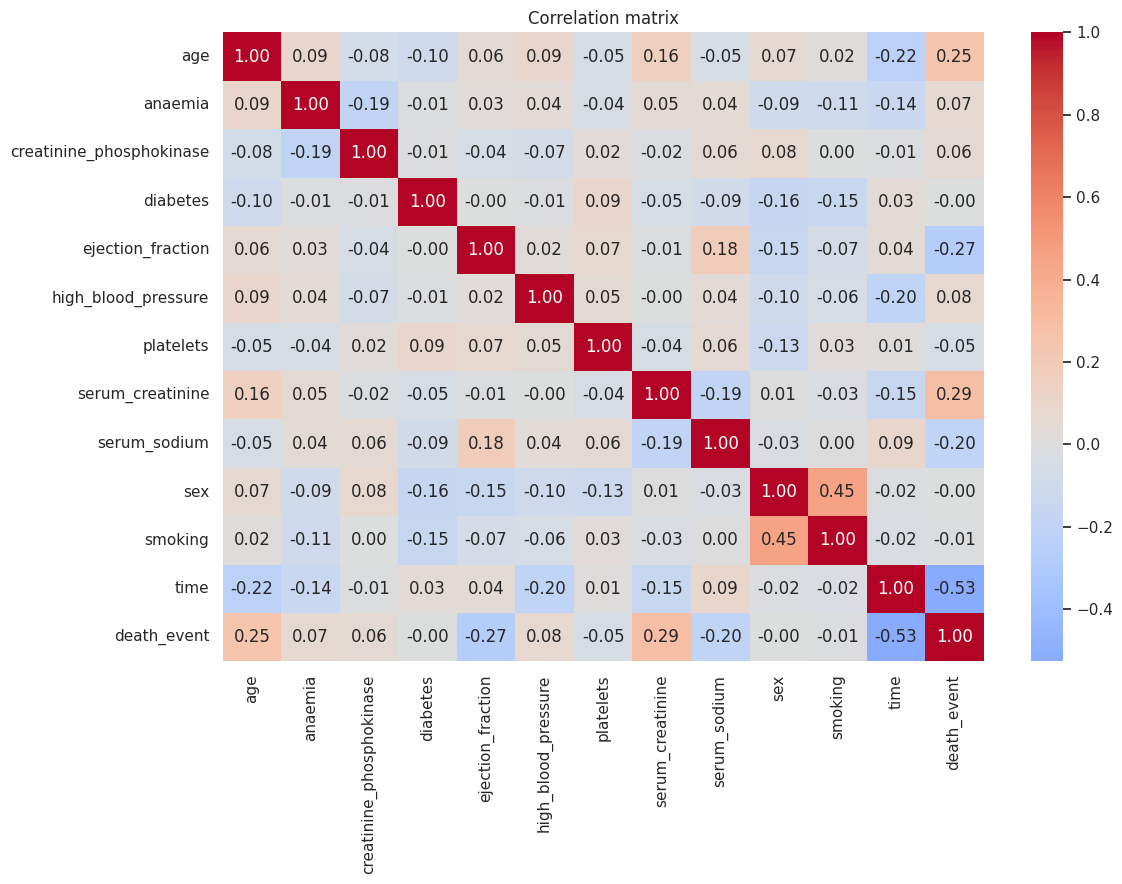

In [8]:
# Correlation heatmap
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation matrix')
plt.tight_layout()
plt.show()

In [9]:
# Drop 'time' to predict death from baseline clinical measurements
X_model = X.drop(columns='time')
y_model = y['death_event']

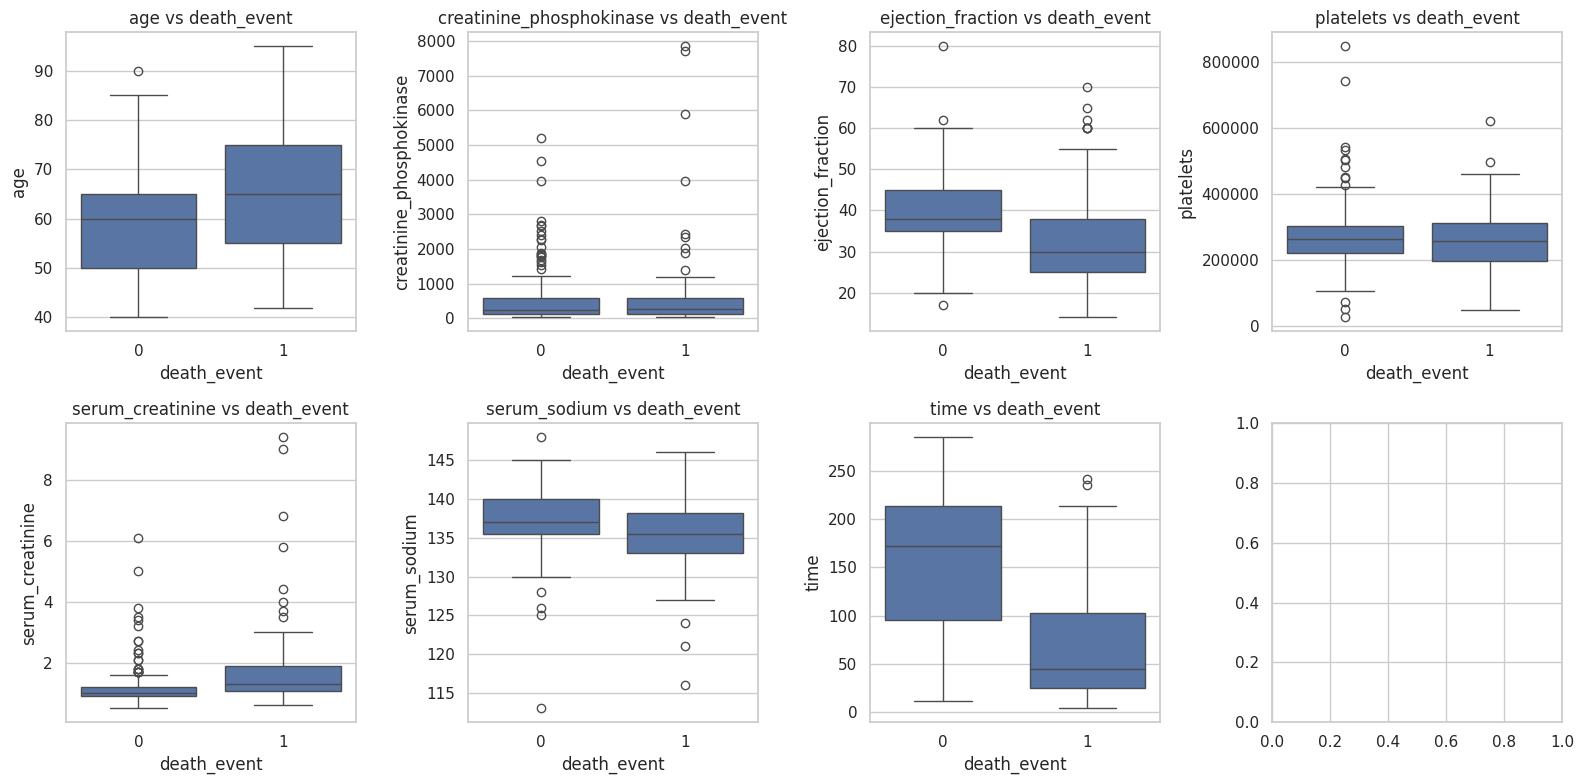

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(x='death_event', y=col, data=df, ax=ax)
    ax.set_title(f'{col} vs death_event')
plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Separate numeric from binary
num_features = ['age', 'creatinine_phosphokinase', 'ejection_fraction',
                'platelets', 'serum_creatinine', 'serum_sodium']
bin_features = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']

# Preprocessor: scale numeric, pass binary through
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('bin', 'passthrough', bin_features),
])

In [12]:
from sklearn.preprocessing import FunctionTransformer

log_transformer = FunctionTransformer(np.log1p, validate=True)

preprocessor = ColumnTransformer([
    ('skewed', log_transformer, ['creatinine_phosphokinase']),
    ('num', StandardScaler(), ['age', 'ejection_fraction',
                                'platelets', 'serum_creatinine', 'serum_sodium']),
    ('bin', 'passthrough', bin_features),
])

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X_model, y_model, test_size=0.2, random_state=42, stratify=y_model
)

In [14]:
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42)),
])

model.fit(X_train, y_train)
print("Model trained!")

Model trained!


In [15]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, ConfusionMatrixDisplay,
)

y_pred  = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

# Metrics
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_proba):.4f}")

Accuracy : 0.7167
Precision: 0.5714
Recall   : 0.4211
F1-score : 0.4848
ROC-AUC  : 0.7548


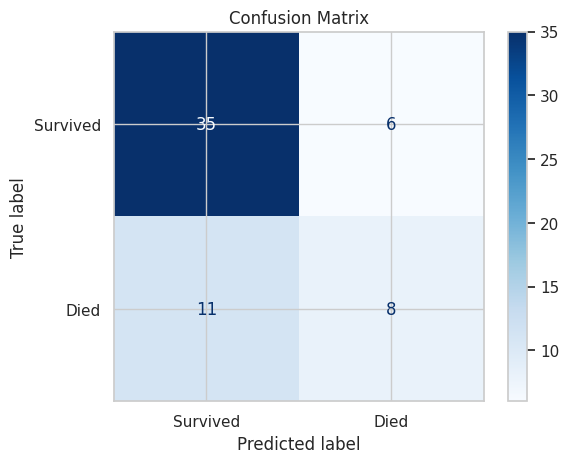

In [16]:
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=['Survived', 'Died'])
disp.plot(cmap='Blues')
plt.title('Confusion Matrix')
plt.show()

In [17]:
print(classification_report(y_test, y_pred, target_names=['Survived', 'Died']))

              precision    recall  f1-score   support

    Survived       0.76      0.85      0.80        41
        Died       0.57      0.42      0.48        19

    accuracy                           0.72        60
   macro avg       0.67      0.64      0.64        60
weighted avg       0.70      0.72      0.70        60



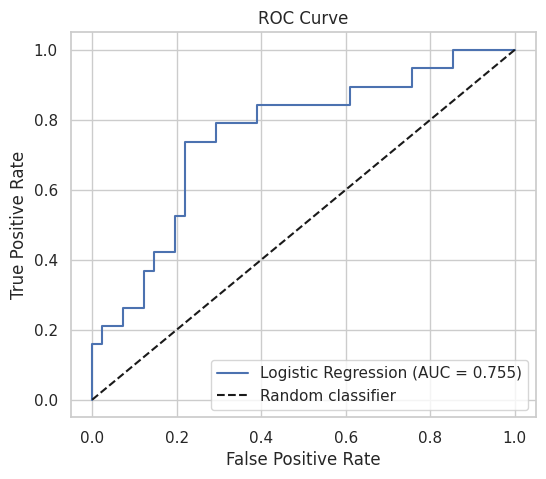

In [18]:
fpr, tpr, _ = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

In [19]:
# Get feature names after preprocessing
feature_names = (
    num_features + bin_features  # column order matches ColumnTransformer
    # (if you used the log-transformer version, adjust accordingly)
)

coefs = model.named_steps['clf'].coef_[0]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefs,
    'Odds Ratio': np.exp(coefs),
}).sort_values('Coefficient', key=np.abs, ascending=False)

print(coef_df)

                     Feature  Coefficient  Odds Ratio
4           serum_creatinine     0.821676    2.274308
2          ejection_fraction    -0.816940    0.441781
8        high_blood_pressure     0.537953    1.712498
1   creatinine_phosphokinase     0.490278    1.632770
6                    anaemia     0.481874    1.619106
7                   diabetes     0.465407    1.592662
10                   smoking     0.331636    1.393246
9                        sex    -0.183786    0.832114
0                        age     0.181713    1.199270
5               serum_sodium    -0.135500    0.873279
3                  platelets    -0.082821    0.920515


/tmp/ipykernel_2470/4130299603.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Coefficient', y='Feature',


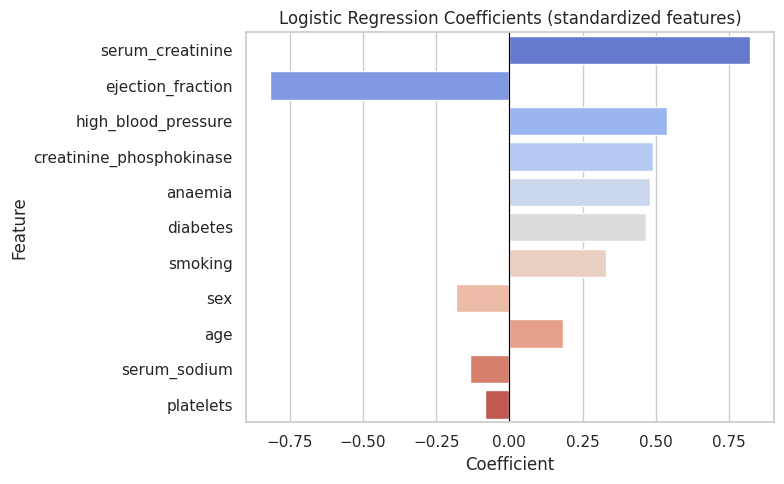

In [20]:
plt.figure(figsize=(8, 5))
sns.barplot(data=coef_df, x='Coefficient', y='Feature',
            palette='coolwarm')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Logistic Regression Coefficients (standardized features)')
plt.tight_layout()
plt.show()